# Regresión del caudal a quince días

La tarea auxiliar de regresión predice el caudal de Calamar en *t* + 15 (m³/s) con los mismos
predictores, las mismas particiones y el mismo motor de experimentos. Además de cumplir la parte
de regresión del Entregable 2, ofrece una lectura complementaria del problema: una regresión
precisa del caudal no garantiza una clasificación precisa de la banda, porque los errores que
importan para la clase son los que ocurren cerca de los límites.

In [1]:
import sys, pickle, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import scipy.stats as st
from myst_nb import glue
from statsmodels.stats.diagnostic import het_white, acorr_ljungbox
from statsmodels.tsa.stattools import bds, acf
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU, COLORES
from src.config import RESULTADOS, DATOS_PROC
from src.analysis import tabla_pliegues, resumen, nombres
from src.models import NOMBRES_MODELO, NOMBRES_OPT
from src.experiment import cargar_datos
D = cargar_datos()
pl = tabla_pliegues("reg_calamar")
res = nombres(resumen(pl, ["rmse", "mae", "r2", "mape"]))
mej = pd.read_csv(RESULTADOS / "mejores_reg.csv")
fin = {r["modelo"]: r for r in pickle.load(open(RESULTADOS / "final_reg.pkl", "rb"))}
fmt = lambda m, s: f"{m:,.1f} ± {s:,.1f}"
vista = res.sort_values("rmse_mean")
pd.DataFrame({"Modelo": vista.nombre, "Optimizador": vista.optimizador_nombre,
              "RMSE (m³/s)": [fmt(a, b) for a, b in zip(vista.rmse_mean, vista.rmse_std)],
              "MAE (m³/s)": [fmt(a, b) for a, b in zip(vista.mae_mean, vista.mae_std)],
              "R²": [f"{a:.3f} ± {b:.3f}" for a, b in zip(vista.r2_mean, vista.r2_std)],
              "MAPE (%)": vista.mape_mean.round(2), "Tiempo total (s)": vista.t_total.round(0)}).reset_index(drop=True)

,Modelo,Optimizador,RMSE (m³/s),MAE (m³/s),R²,MAPE (%),Tiempo total (s)
0,SVR,Bayesiana (TPE),575.7 ± 73.6,455.2 ± 63.2,0.939 ± 0.025,7.55,17135.0
1,SVR,Random,579.6 ± 72.1,458.2 ± 63.0,0.939 ± 0.025,7.59,9880.0
2,XGBoost,Random,584.0 ± 70.5,460.8 ± 60.6,0.938 ± 0.023,7.66,2071.0
3,XGBoost,Genética (DEAP),586.7 ± 66.5,463.9 ± 58.0,0.938 ± 0.022,7.75,2562.0
4,SVR,Genética (DEAP),587.6 ± 73.3,466.4 ± 64.2,0.937 ± 0.024,7.85,14785.0
5,SVR,Grid,588.7 ± 65.9,465.3 ± 59.5,0.937 ± 0.025,7.67,12465.0
6,XGBoost,Bayesiana (TPE),600.3 ± 74.9,477.7 ± 65.8,0.934 ± 0.027,7.94,1135.0
7,Random Forest,Random,614.0 ± 79.2,485.9 ± 64.1,0.931 ± 0.027,8.15,2022.0
8,Random Forest,Genética (DEAP),616.6 ± 83.3,486.3 ± 64.4,0.931 ± 0.027,8.15,2480.0
9,XGBoost,Grid,621.7 ± 74.2,493.9 ± 60.5,0.929 ± 0.029,8.16,2771.0


## Métricas en la prueba reservada

In [2]:
yte = D.y_reg_test.values
q_pers = np.sqrt(D.X_test.calamar_cuad.values)
filas = [{"Modelo": "Persistencia (Q(t+15) = Q(t))", "Optimizador": "—",
          "RMSE": np.sqrt(np.mean((yte - q_pers) ** 2)), "MAE": np.mean(np.abs(yte - q_pers)), "R²": 1 - np.sum((yte - q_pers) ** 2) / np.sum((yte - yte.mean()) ** 2)}]
pruebas = []
for m in mej.sort_values("rmse_mean").modelo:
    r = fin[m]; e = yte - r["pred_test"]
    filas.append({"Modelo": NOMBRES_MODELO[m], "Optimizador": NOMBRES_OPT[r["optimizador"]], "RMSE": r["metricas_test"]["rmse"],
                  "MAE": r["metricas_test"]["mae"], "R²": r["metricas_test"]["r2"]})
    exog = np.column_stack([np.ones(len(e)), r["pred_test"] / 1e4])
    pw = het_white(e, exog)[1]
    sub = e[::15][:400]                      # submuestra cada 15 días: BDS es O(n²)
    pb = bds((sub - sub.mean()) / sub.std(), max_dim=3)[1]
    plb = acorr_ljungbox(e, lags=[15], return_df=True).lb_pvalue.iloc[0]
    pj = st.jarque_bera(e).pvalue
    pruebas.append({"Modelo": NOMBRES_MODELO[m], "RMSE": r["metricas_test"]["rmse"], "MAE": r["metricas_test"]["mae"],
                    "p (White)": pw, "p (BDS, m=2)": pb[0], "p (BDS, m=3)": pb[1], "p (Ljung-Box, 15)": plb,
                    "p (Jarque-Bera)": pj, "ACF(1) del residuo": acf(e, nlags=1)[1]})
tab_test = pd.DataFrame(filas)
tab_prue = pd.DataFrame(pruebas)
mejor_reg = mej.sort_values("rmse_mean").iloc[0].modelo
glue("reg_mejor", NOMBRES_MODELO[mejor_reg], display=False)
glue("reg_rmse", float(fin[mejor_reg]["metricas_test"]["rmse"]), display=False)
glue("reg_rmse_pers", float(tab_test.RMSE.iloc[0]), display=False)
glue("reg_acf1", float(tab_prue.set_index("Modelo").loc[NOMBRES_MODELO[mejor_reg], "ACF(1) del residuo"]), display=False)
tab_test.round(3)

,Modelo,Optimizador,RMSE,MAE,R²
0,Persistencia (Q(t+15) = Q(t)),—,984.829,775.660,0.873
1,SVR,Bayesiana (TPE),642.767,495.390,0.946
2,XGBoost,Random,641.024,496.047,0.946
3,Random Forest,Random,667.209,517.344,0.942
4,Ridge,Grid,682.335,532.091,0.939
5,Lasso,Random,681.291,531.532,0.939
6,KNN,Grid,756.342,587.660,0.925
7,Árbol de decisión,Random,758.904,597.540,0.925


In [3]:
tab_prue.round(4)

,Modelo,RMSE,MAE,p (White),"p (BDS, m=2)","p (BDS, m=3)","p (Ljung-Box, 15)",p (Jarque-Bera),ACF(1) del residuo
0,SVR,642.7675,495.3901,0.0000,0.0006,0.0004,0.0,0.0000,0.9662
1,XGBoost,641.0237,496.0472,0.0000,0.0000,0.0001,0.0,0.0000,0.9563
2,Random Forest,667.2088,517.3440,0.0000,0.0001,0.0001,0.0,0.0000,0.9724
3,Ridge,682.3353,532.0907,0.0000,0.0002,0.0004,0.0,0.0000,0.9812
4,Lasso,681.2912,531.5321,0.0000,0.0000,0.0003,0.0,0.0000,0.9836
5,KNN,756.3423,587.6596,0.0000,0.0000,0.0000,0.0,0.0001,0.9792
6,Árbol de decisión,758.9041,597.5402,0.0003,0.0000,0.0000,0.0,0.0046,0.8584


La mejor combinación en el bucle externo es {glue:text}`reg_mejor` con optimización bayesiana,
seguida de cerca por XGBoost. En la prueba reservada ambas alcanzan un RMSE cercano a 640 m³/s y
un R² de 0,946, frente a un RMSE de {glue:text}`reg_rmse_pers:,.0f` m³/s de la persistencia: los
modelos reducen el error de predicción a quince días en alrededor de un tercio. Los modelos
lineales (Ridge y Lasso) quedan cerca, a unos 40 m³/s, lo que indica que buena parte de la
señal del caudal futuro es lineal en el estado reciente; la no linealidad pesa mucho más en la
clasificación de la banda que en la regresión del caudal, y esa asimetría es la que motiva el
modelo original.

Las pruebas de supuestos rechazan la homocedasticidad (White), la independencia (BDS y
Ljung-Box) y la normalidad (Jarque-Bera) en todos los modelos, y la autocorrelación de orden uno
del residuo del mejor modelo es {glue:text}`reg_acf1:.2f`. Ese resultado no es, por sí mismo,
señal de mala especificación: con un horizonte de quince días, los errores de días consecutivos
comparten catorce de sus quince días de evolución no observada, de modo que el residuo tiene por
construcción una estructura de media móvil de orden catorce. La consecuencia práctica es que
ninguna comparación entre modelos de regresión puede tratar los errores diarios como
independientes, y por eso la sección de comparación estadística usa estadísticos con varianza
de largo plazo y bootstrap estacionario.

## Entrenamiento, validación y prueba

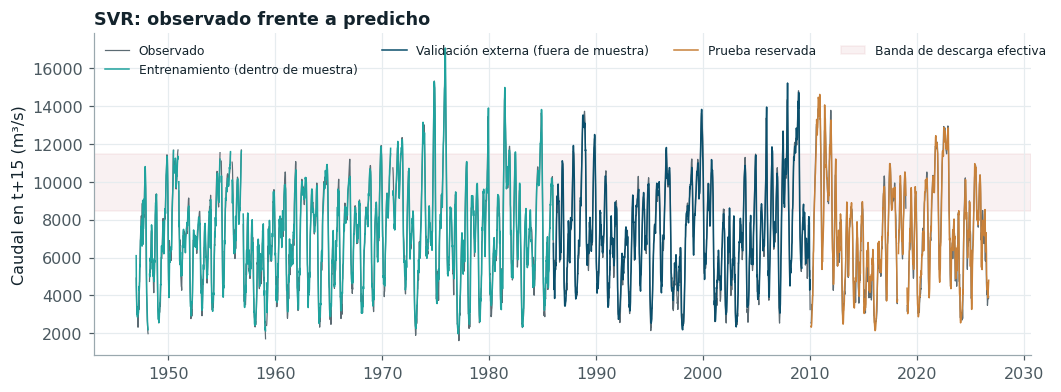

In [4]:
r = fin[mejor_reg]
fmej = mej.set_index("modelo").loc[mejor_reg]
from src.analysis import cargar_carpeta
val = [x for x in cargar_carpeta("reg_calamar")
       if x["modelo"] == mejor_reg and x["optimizador"] == fmej.optimizador]
idx_val = np.concatenate([x["idx_test"] for x in val]); p_val = np.concatenate([x["pred"] for x in val])
ser = pd.DataFrame({"fecha": D.fechas, "obs": D.y_reg.values, "ajuste": r["pred_train"]})
ser["validacion"] = np.nan; ser.loc[idx_val, "validacion"] = p_val
tes = pd.DataFrame({"fecha": D.fechas_test.values, "obs": yte, "prueba": r["pred_test"]})
fig, ax = plt.subplots(figsize=(11, 3.8))
s1 = ser.set_index("fecha").resample("W").mean(); s2 = tes.set_index("fecha").resample("W").mean()
ax.plot(s1.index, s1.obs, color=NEU, lw=.8, label="Observado")
ax.plot(s2.index, s2.obs, color=NEU, lw=.8)
ax.plot(s1[s1.index < "1986"].index, s1[s1.index < "1986"].ajuste, color=CAU, lw=1, label="Entrenamiento (dentro de muestra)")
ax.plot(s1.index, s1.validacion, color=RIO, lw=1, label="Validación externa (fuera de muestra)")
ax.plot(s2.index, s2.prueba, color=SED, lw=1, label="Prueba reservada")
import json
LIM = json.loads((DATOS_PROC / "parametros.json").read_text(encoding="utf-8"))["calamar"]["LIM"]
yte = np.asarray(yte)
ax.axhspan(*LIM, color=ALE, alpha=.07, label="Banda de descarga efectiva")
ax.set(ylabel="Caudal en t+15 (m³/s)", title=f"{NOMBRES_MODELO[mejor_reg]}: observado frente a predicho")
ax.legend(ncol=4, fontsize=8, loc="upper left"); plt.show()

In [5]:
# Error por segmento y frente a la persistencia, y acierto del lado de la banda en la prueba
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
q_act = np.sqrt(D.X.calamar_cuad.values); q_act_te = np.sqrt(D.X_test.calamar_cuad.values)
seg = pd.DataFrame([
    {"segmento": "Entrenamiento 1947-2009 (dentro de muestra)", "RMSE modelo": rmse(D.y_reg.values, r["pred_train"]),
     "RMSE persistencia": rmse(D.y_reg.values, q_act)},
    {"segmento": "Validación externa 1986-2009 (fuera de muestra)", "RMSE modelo": rmse(D.y_reg.values[idx_val], p_val),
     "RMSE persistencia": rmse(D.y_reg.values[idx_val], q_act[idx_val])},
    {"segmento": "Prueba reservada 2010-2026", "RMSE modelo": rmse(yte, r["pred_test"]),
     "RMSE persistencia": rmse(yte, q_act_te)}])
seg["reducción frente a la persistencia"] = 1 - seg["RMSE modelo"] / seg["RMSE persistencia"]
mej_blq = [1 - rmse(x["y_test"], x["pred"]) / rmse(x["y_test"], q_act[x["idx_test"]]) for x in val]
dentro = lambda q: (q >= LIM[0]) & (q <= LIM[1])
d_lim = np.minimum(np.abs(yte - LIM[0]), np.abs(yte - LIM[1])) / json.loads(
    (DATOS_PROC / "parametros.json").read_text(encoding="utf-8"))["calamar"]["Q_EF"]
lado = dentro(r["pred_test"]) == dentro(yte)
for k, v in zip(("tr", "val", "te"), seg["RMSE modelo"]):
    glue(f"seg_rmse_{k}", v, display=False)
glue("mejora_blq_min", float(min(mej_blq)), display=False); glue("mejora_blq_max", float(max(mej_blq)), display=False)
glue("lado_global", float(lado.mean()), display=False)
glue("lado_borde", float(lado[d_lim < .05].mean()), display=False)
glue("lado_lejos", float(lado[d_lim > .20].mean()), display=False)
seg.round(3)

,segmento,RMSE modelo,RMSE persistencia,reducción frente a la persistencia
0,Entrenamiento 1947-2009 (dentro de muestra),612.722,1044.298,0.413
1,Validación externa 1986-2009 (fuera de muestra),580.289,1021.987,0.432
2,Prueba reservada 2010-2026,642.767,984.829,0.347


La {numref}`fig-reg-series` y la tabla anterior permiten evaluar el sobreajuste y la estabilidad
temporal del mejor regresor. El error dentro de muestra en el entrenamiento
({glue:text}`seg_rmse_tr:,.0f` m³/s) es del mismo orden que el error fuera de muestra en la
validación externa ({glue:text}`seg_rmse_val:,.0f` m³/s) y en la prueba reservada
({glue:text}`seg_rmse_te:,.0f` m³/s), lo que descarta un sobreajuste apreciable: la
regularización del modelo, elegida en la validación anidada, limita su capacidad a la estructura
que se repite entre décadas. La reducción del error frente a la persistencia se mantiene en todos
los bloques externos, entre el {glue:text}`mejora_blq_min:.0%` y el
{glue:text}`mejora_blq_max:.0%`, y no se degrada en la prueba, de modo que la relación aprendida no
depende de un periodo particular. En la figura, las mayores desviaciones coinciden con los picos
de las crecidas y con los ascensos abruptos desde el estiaje, que el estado actual del río no
anticipa.

Para la tarea de clasificación interesa además si el caudal previsto cae del lado correcto de los
límites de la banda. En la prueba, el regresor acierta el lado en el
{glue:text}`lado_global:.1%` de los días; el acierto es del {glue:text}`lado_lejos:.0%` cuando el
caudal observado queda a más del 20 % de $Q_{ef}$ de un límite y cae al
{glue:text}`lado_borde:.1%` cuando queda a menos del 5 %. Un error de unos 640 m³/s, pequeño en
términos relativos, basta para cambiar la clase de los días próximos a los límites, que es donde
se concentran los errores de todos los clasificadores.

## Análisis de residuos

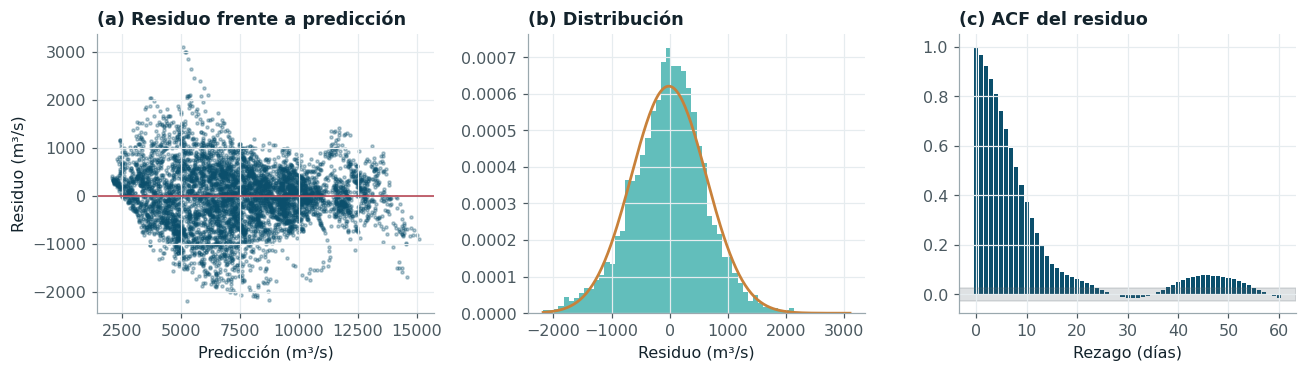

In [6]:
e = yte - r["pred_test"]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
axs[0].scatter(r["pred_test"], e, s=4, alpha=.3, color=RIO); axs[0].axhline(0, color=ALE, lw=1)
axs[0].set(xlabel="Predicción (m³/s)", ylabel="Residuo (m³/s)", title="(a) Residuo frente a predicción")
axs[1].hist(e, bins=60, density=True, color=CAU, alpha=.7)
xx = np.linspace(e.min(), e.max(), 200); axs[1].plot(xx, st.norm.pdf(xx, e.mean(), e.std()), color=SED)
axs[1].set(xlabel="Residuo (m³/s)", title="(b) Distribución")
a = acf(e, nlags=60, fft=True); axs[2].bar(range(61), a, color=RIO, width=.8)
axs[2].axhspan(-1.96 / np.sqrt(len(e)), 1.96 / np.sqrt(len(e)), color=NEU, alpha=.2)
axs[2].set(xlabel="Rezago (días)", title="(c) ACF del residuo")
plt.tight_layout(); plt.show()
corr_het = st.spearmanr(np.abs(e), r["pred_test"])[0]
glue("corr_het", float(corr_het), display=False)
glue("kurt_res", float(st.kurtosis(e)), display=False)

La autocorrelación del residuo decae hasta anularse hacia los rezagos 20 a 25
({numref}`fig-residuos`c), como corresponde a la estructura de media móvil descrita. El diagrama
de residuo frente a predicción no muestra un sesgo sistemático en la mayor parte del rango, salvo
por encima de unos 12.500 m³/s, donde los residuos son mayoritariamente negativos: el modelo
sobreestima las crecidas mayores, que en el entrenamiento son pocas. Muestra también
heterocedasticidad: la correlación de Spearman entre el error absoluto y la predicción es
{glue:text}`corr_het:.2f`, de modo que los errores grandes se concentran en caudales previstos
bajos e intermedios, que corresponden a los ascensos rápidos desde el estiaje que el estado actual
anticipa mal. La curtosis en exceso del residuo es {glue:text}`kurt_res:.2f`, con colas algo más
pesadas que la normal. Ambos rasgos son relevantes para el modelo original: una dispersión que
cambia con el estado del río es justamente lo que BLGB modela con su segundo ensamble, el del
logaritmo de σ.